In [7]:
import pandas as pd
from pathlib import Path

project_dir = Path.home() / "Downloads" / "Hate-Speech-Detection"
data_dir = project_dir / "data" / "processed"

train_df = pd.read_csv(data_dir / "hatexplain_train.csv")
val_df = pd.read_csv(data_dir / "hatexplain_validation.csv")
test_df = pd.read_csv(data_dir / "hatexplain_test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df[["text", "label", "label_name"]].head()

Train: (15383, 6)
Validation: (1922, 6)
Test: (1924, 6)


,text,label,label_name
0,u really think i would not have been raped by ...,2,Offensive
1,the uk has threatened to return radioactive wa...,2,Offensive
2,if english is not imposition then hindi is als...,2,Offensive
3,no liberal congratulated hindu refugees post c...,2,Offensive
4,he said bro even your texts sound redneck what...,2,Offensive


In [2]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: /Users/aadya/Downloads/Hate-Speech-Detection
Files here: ['requirements.txt', 'docs', 'README.md', 'results', '.gitignore', 'configs', '.venv', '02_Baseline_Classifier.ipynb.ipynb', '.ipynb_checkpoints', '.git', 'data', 'notebooks', 'src']


In [3]:
import pandas as pd
from pathlib import Path

project_dir = Path.home() / "Downloads" / "Hate-Speech-Detection"
data_dir = project_dir / "data" / "processed"

train_df = pd.read_csv(data_dir / "hatexplain_train.csv")
val_df = pd.read_csv(data_dir / "hatexplain_validation.csv")
test_df = pd.read_csv(data_dir / "hatexplain_test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df[["text", "label", "label_name"]].head()

Train: (15383, 6)
Validation: (1922, 6)
Test: (1924, 6)


,text,label,label_name
0,u really think i would not have been raped by ...,2,Offensive
1,the uk has threatened to return radioactive wa...,2,Offensive
2,if english is not imposition then hindi is als...,2,Offensive
3,no liberal congratulated hindu refugees post c...,2,Offensive
4,he said bro even your texts sound redneck what...,2,Offensive


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, f1_score

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(train_df["text"], train_df["label"])

print("Baseline model trained successfully!")

Baseline model trained successfully!


Validation Accuracy: 0.6498
Validation Macro-F1: 0.6309

Classification Report:
              precision    recall  f1-score   support

 Hate speech       0.73      0.70      0.72       593
      Normal       0.64      0.78      0.70       781
   Offensive       0.56      0.41      0.48       548

    accuracy                           0.65      1922
   macro avg       0.64      0.63      0.63      1922
weighted avg       0.65      0.65      0.64      1922



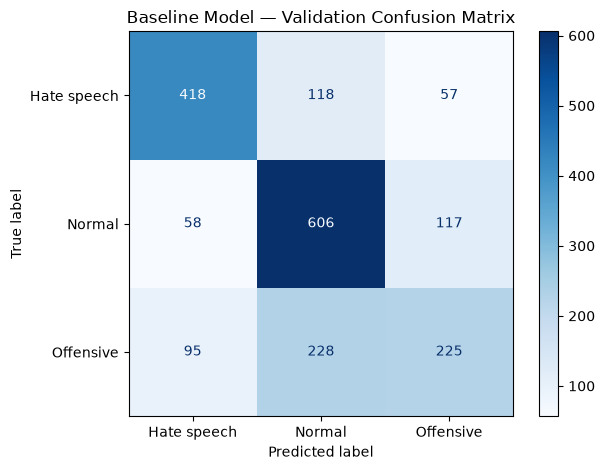

In [9]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

val_predictions = model.predict(val_df["text"])

print("Validation Accuracy:", round(
    accuracy_score(val_df["label"], val_predictions), 4
))

print("Validation Macro-F1:", round(
    f1_score(val_df["label"], val_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    val_df["label"],
    val_predictions,
    labels=[0, 1, 2],
    target_names=["Hate speech", "Normal", "Offensive"],
    zero_division=0
))

cm = confusion_matrix(val_df["label"], val_predictions, labels=[0, 1, 2])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Hate speech", "Normal", "Offensive"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Model — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

precision, recall, f1, support = precision_recall_fscore_support(
    val_df["label"],
    val_predictions,
    labels=[0, 1, 2],
    zero_division=0
)

results = pd.DataFrame({
    "Class": ["Hate speech", "Normal", "Offensive"],
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

results.to_csv(
    project_dir / "results" / "tables" / "baseline_metrics.csv",
    index=False
)

results

,Class,Precision,Recall,F1-score,Support
0,Hate speech,0.732049,0.704890,0.718213,593
1,Normal,0.636555,0.775928,0.699365,781
2,Offensive,0.563910,0.410584,0.475185,548
